# LDA topic models: Official media
Fit six topic counts to the preprocessed marriage-discussion corpus. Each result is saved separately.

## 1. Load the data
Use the existing `tokens` and `year` columns; the source CSV is not changed.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

project = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "notebook").is_dir() and (p / "data").is_dir())
source = project / "data" / "official_media_analysis.csv"
output = project / "data" / "analysis_results" / "lda_official_media"
(project / "data" / "generated_figures" / output.relative_to(project / "data" / "analysis_results")).mkdir(parents=True, exist_ok=True)
(project / "data" / "model_cache" / output.relative_to(project / "data" / "analysis_results")).mkdir(parents=True, exist_ok=True)
output.mkdir(parents=True, exist_ok=True)
data = pd.read_csv(source, usecols=["tokens", "year"]).dropna(subset=["tokens"]).reset_index(drop=True)
texts = data["tokens"]
print(f"Documents loaded: {len(data):,}")


Documents loaded: 2,020


## 2. Count words
Use the preprocessed words. Keep words found in at least 5 documents, and cap the vocabulary at 5,000 words.

In [2]:
vectorizer = CountVectorizer(
    tokenizer=str.split, token_pattern=None, lowercase=False,
    min_df=5, max_df=0.85, max_features=5000
)
X = vectorizer.fit_transform(texts)
keep = X.getnnz(axis=1) > 0
X = X[keep]
data = data.loc[keep].reset_index(drop=True)
words = vectorizer.get_feature_names_out()
print(f"Documents used: {X.shape[0]:,}; vocabulary: {X.shape[1]:,} words")


Documents used: 2,020; vocabulary: 5,000 words


## 3. Fit and save the models
Try 8, 10, 12, 15, 20, and 25 topics. Each table shows the top 10 words for every topic. Compare whether the topics are clear and distinct; more topics are not automatically better.

In [3]:
topic_counts = [8, 10, 12, 15, 20, 25]
for k in topic_counts:
    model = LatentDirichletAllocation(
        n_components=k, learning_method="online", max_iter=12,
        batch_size=512, random_state=42, n_jobs=4
    )
    model.fit(X)
    top_indices = model.components_.argsort(axis=1)[:, -10:][:, ::-1]
    table = pd.DataFrame(words[top_indices], columns=[f"keyword_{i}" for i in range(1, 11)])
    table.insert(0, "topic", range(1, k + 1))
    if k == 12:
        k12_probabilities = model.transform(X)
        k12_keywords = table.copy()
    table.to_csv(output / f"k{k}_top10_keywords.csv", index=False, encoding="utf-8-sig")
    print(f"{k} topics — saved to {output / f'k{k}_top10_keywords.csv'}")
    display(table)


8 topics — saved to /Users/jingwenzhai/Desktop/Fightin Words/结果/lda_official_media/k8_top10_keywords.csv


,topic,keyword_1,keyword_2,keyword_3,keyword_4,keyword_5,keyword_6,keyword_7,keyword_8,keyword_9,keyword_10
0,1,彩礼,返还,生活,给付,情况,婚姻,法院,财物,结婚,纠纷
1,2,结婚,婚姻,家庭,女性,父母,孩子,人数,生活,年轻人,韩国
2,3,生育,妇女,社会,政策,部门,服务,保障,条例,结婚,女性
3,4,婚姻登记,办理,服务,结婚登记,新人,登记,机关,民政局,当事人,跨省通办
4,5,彩礼,农村,高价彩礼,高额,移风易俗,治理,村民,家庭,结婚,零彩礼
5,6,文明,活动,移风易俗,工作,婚礼,婚俗,家庭,文化,服务,新人
6,7,相亲,青年,婚恋,恋爱,活动,年轻人,平台,单身,爱情,交友
7,8,离婚,法院,案件,子女,夫妻,财产,婚姻,家庭暴力,一方,人民法院


10 topics — saved to /Users/jingwenzhai/Desktop/Fightin Words/结果/lda_official_media/k10_top10_keywords.csv


,topic,keyword_1,keyword_2,keyword_3,keyword_4,keyword_5,keyword_6,keyword_7,keyword_8,keyword_9,keyword_10
0,1,彩礼,返还,生活,给付,情况,婚姻,财物,法院,习俗,女方
1,2,婚姻,结婚,家庭,父母,生活,孩子,女性,工作,年轻人,两人
2,3,生育,婚姻登记,结婚,政策,人口,登记,妇女,建议,条例,社会
3,4,婚姻登记,办理,结婚登记,新人,服务,登记,机关,民政局,跨省通办,当事人
4,5,彩礼,农村,高额,高价彩礼,治理,移风易俗,村民,家庭,零彩礼,结婚
5,6,文明,移风易俗,活动,婚礼,婚俗,文化,婚俗改革,新人,新风,群众
6,7,青年,相亲,活动,恋爱,婚恋,年轻人,单身,爱情,交友,情感
7,8,离婚,法院,财产,子女,夫妻,一方,判决,婚姻,民法典,人民法院
8,9,调解,家庭,家庭暴力,工作,纠纷,婚姻家庭,离婚,矛盾,案件,社会
9,10,平台,服务,诈骗,信息,婚恋,婚介,相亲,公司,结婚,红娘


12 topics — saved to /Users/jingwenzhai/Desktop/Fightin Words/结果/lda_official_media/k12_top10_keywords.csv


...

,topic,keyword_1,keyword_2,keyword_3,keyword_4,keyword_5,keyword_6,keyword_7,keyword_8,keyword_9,keyword_10
0,1,彩礼,返还,生活,给付,情况,婚姻,法院,财物,习俗,女方
1,2,结婚,婚姻,父母,婚礼,孩子,生活,家庭,年轻人,工作,两人
2,3,生育,政策,妇女,婚育,服务,女性,保障,条例,社会,人口
3,4,婚姻登记,新人,服务,登记,办理,民政局,结婚登记,预约,颁证,结婚
4,5,彩礼,农村,高额,高价彩礼,治理,村民,移风易俗,家庭,零彩礼,结婚
5,6,文明,移风易俗,婚俗,婚俗改革,活动,新风,群众,文化,宣传,工作
6,7,青年,活动,相亲,单身,年轻人,婚恋,交友,恋爱,职工,爱情
7,8,离婚,法院,子女,财产,夫妻,一方,民法典,判决,房屋,婚姻
8,9,家庭暴力,人身安全保护令,家暴,保护,法院,申请,实施,妇女,离婚,人民法院
9,10,结婚,服务,婚恋,婚姻,婚介,女性,韩国,机构,显示,公司


20 topics — saved to /Users/jingwenzhai/Desktop/Fightin Words/结果/lda_official_media/k20_top10_keywords.csv


,topic,keyword_1,keyword_2,keyword_3,keyword_4,keyword_5,keyword_6,keyword_7,keyword_8,keyword_9,keyword_10
0,1,疫情,结婚,妻子,刘某,两人,婚礼,工作,丈夫,防控,一名
1,2,结婚,婚姻,父母,家庭,孩子,生活,年轻人,工作,催婚,选择
2,3,生育,政策,妇女,服务,女性,婚育,保障,条例,国家,支持
3,4,婚姻登记,新人,服务,登记,民政局,结婚登记,颁证,仪式,预约,结婚
4,5,相亲,红娘,家长,对象,信息,工作,条件,父母,阿姨,年龄
5,6,文明,活动,婚俗,婚俗改革,移风易俗,文化,新风,家庭,群众,婚姻
6,7,青年,活动,相亲,单身,交友,年轻人,职工,婚恋,联谊,受访
7,8,离婚,法院,财产,夫妻,一方,子女,房屋,判决,分割,民法典
8,9,家庭暴力,人身安全保护令,家暴,未成年人,法院,保护,案件,离婚,申请,实施
9,10,结婚,婚姻,年轻人,婚恋,女性,社会,婚礼,韩国,教育,男性


25 topics — saved to /Users/jingwenzhai/Desktop/Fightin Words/结果/lda_official_media/k25_top10_keywords.csv


,topic,keyword_1,keyword_2,keyword_3,keyword_4,keyword_5,keyword_6,keyword_7,keyword_8,keyword_9,keyword_10
0,1,李某,王某,刘某,法院,恋爱,转账,赠与,期间,赵某,结婚
1,2,结婚,年轻人,父母,婚姻,婚礼,生活,催婚,女性,家庭,选择
2,3,生育,政策,妇女,婚育,女性,服务,保障,人口,支持,国家
3,4,新人,婚姻登记,服务,登记,民政局,结婚登记,颁证,仪式,结婚,领证
4,5,相亲,信息,对象,征婚,年龄,条件,婚恋,社区,工作,中老年人
5,6,文明,移风易俗,婚俗,活动,婚俗改革,新风,群众,文化,家庭,宣传
6,7,青年,活动,相亲,单身,交友,职工,婚恋,嘉宾,联谊,年轻人
7,8,离婚,法院,财产,夫妻,一方,子女,房屋,分割,民法典,婚姻
8,9,残疾人,社会,实体,康复,服务,金融机构,彩礼,创新,经济,金融
9,10,结婚,韩国,女性,男性,直播间,人口,显示,人数,数据,单身


## 4. Topic prevalence for K = 12
Prevalence is the average topic probability across documents. Each document has equal weight. The yearly table uses the same measure within each year.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Arial Unicode MS"
labels = [f"T{i + 1}  " + " · ".join(k12_keywords.iloc[i, 1:4]) for i in range(12)]
dominant = k12_probabilities.argmax(axis=1)
overall = pd.DataFrame({
    "topic": range(1, 13),
    "top_keywords": [" / ".join(k12_keywords.iloc[i, 1:11]) for i in range(12)],
    "prevalence_pct": (k12_probabilities.mean(axis=0) * 100).round(2),
    "dominant_documents": np.bincount(dominant, minlength=12),
})
overall["dominant_doc_pct"] = (overall["dominant_documents"] / len(data) * 100).round(2)
overall.to_csv(output / "k12_topic_prevalence.csv", index=False, encoding="utf-8-sig")

rows = []
for year in sorted(data["year"].dropna().astype(int).unique()):
    mask = data["year"].to_numpy() == year
    for topic, share in enumerate(k12_probabilities[mask].mean(axis=0), start=1):
        rows.append({"year": year, "topic": topic, "prevalence_pct": round(share * 100, 2),
                     "n_documents": int(mask.sum())})
yearly = pd.DataFrame(rows)
yearly.to_csv(output / "k12_topic_by_year.csv", index=False, encoding="utf-8-sig")
print("Overall topic prevalence (%)")
display(overall[["topic", "top_keywords", "prevalence_pct", "dominant_doc_pct"]])
print("Topic prevalence by year (%)")
display(yearly.pivot(index="topic", columns="year", values="prevalence_pct"))


Overall topic prevalence (%)


,topic,top_keywords,prevalence_pct,dominant_doc_pct
0,1,彩礼 / 返还 / 生活 / 给付 / 情况 / 婚姻 / 财物 / 法院 / 女方 / 结婚,5.12,5.10
1,2,婚姻 / 结婚 / 家庭 / 生活 / 父母 / 年轻人 / 女性 / 孩子 / 工作 / 社会,10.52,10.74
2,3,生育 / 婚姻登记 / 政策 / 结婚 / 登记 / 妇女 / 建议 / 条例 / 人口 / 撤销,4.54,4.36
3,4,婚姻登记 / 办理 / 结婚登记 / 新人 / 服务 / 登记 / 机关 / 跨省通办 / ...,17.74,18.76
4,5,彩礼 / 农村 / 移风易俗 / 高价彩礼 / 治理 / 高额 / 村民 / 工作 / 文明...,9.73,10.64
5,6,文明 / 婚礼 / 活动 / 婚俗 / 新人 / 文化 / 婚俗改革 / 婚姻 / 服务 /...,15.85,15.84
6,7,青年 / 活动 / 相亲 / 恋爱 / 婚恋 / 单身 / 年轻人 / 交友 / 爱情 / 职工,8.31,7.97
7,8,离婚 / 法院 / 子女 / 财产 / 夫妻 / 一方 / 婚姻 / 判决 / 民法典 / 协议,8.55,8.47
8,9,家庭暴力 / 人身安全保护令 / 家暴 / 离婚 / 保护 / 申请 / 法院 / 实施 /...,1.93,1.63
9,10,服务 / 平台 / 相亲 / 结婚 / 婚介 / 婚恋 / 公司 / 信息 / 红娘 / 人数,7.09,6.83


Topic prevalence by year (%)


year,2021,2022,2023,2024,2025
topic,,,,,
1,2.12,1.52,4.90,12.82,5.53
2,18.28,13.16,9.72,6.61,4.25
3,8.66,3.67,4.34,4.35,2.79
4,15.28,17.54,24.55,10.41,22.15
5,4.84,10.03,10.19,12.44,10.04
6,7.87,18.24,12.96,17.70,19.38
7,9.16,10.29,3.98,7.62,8.98
8,8.13,7.08,9.84,10.09,8.50
9,3.61,1.31,2.32,2.39,0.67


## 5. Make the charts
The bar chart shows overall topic prevalence. The heatmap shows how it changes by year. Topic labels use the first three keywords.

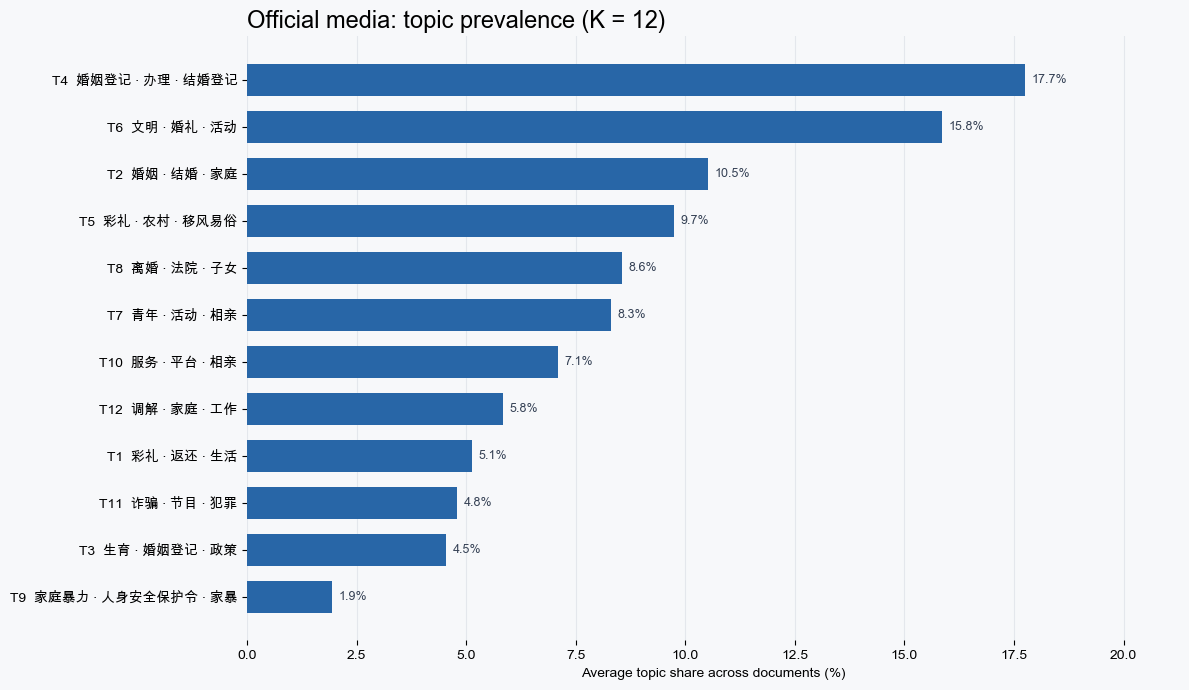

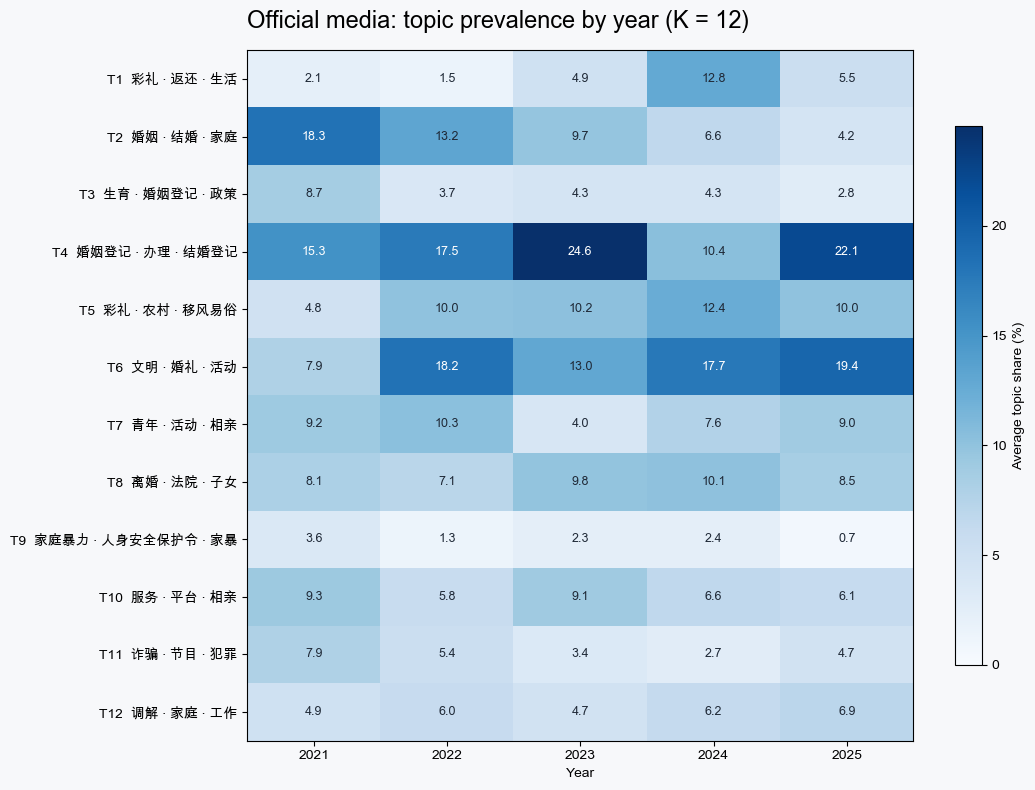

In [5]:
order = np.argsort(overall["prevalence_pct"].to_numpy())
fig, ax = plt.subplots(figsize=(12, 7), facecolor="#f7f8fa")
ax.set_facecolor("#f7f8fa")
ax.barh([labels[i] for i in order], overall["prevalence_pct"].iloc[order], color="#2866a7", height=0.68)
for y, value in enumerate(overall["prevalence_pct"].iloc[order]):
    ax.text(value + 0.15, y, f"{value:.1f}%", va="center", fontsize=9, color="#344054")
ax.set_xlim(0, overall["prevalence_pct"].max() * 1.20)
ax.set_xlabel("Average topic share across documents (%)")
ax.set_title("Official media: topic prevalence (K = 12)", loc="left", fontsize=17, fontweight="bold")
ax.grid(axis="x", color="#e4e7ec")
ax.set_axisbelow(True)
for spine in ax.spines.values(): spine.set_visible(False)
fig.tight_layout()
fig.savefig((project / "data" / "generated_figures" / output.relative_to(project / "data" / "analysis_results")) / "k12_topic_prevalence.png", dpi=180, facecolor=fig.get_facecolor())
plt.show()

grid = yearly.pivot(index="topic", columns="year", values="prevalence_pct").reindex(range(1, 13))
fig, ax = plt.subplots(figsize=(11, 8), facecolor="#f7f8fa")
image = ax.imshow(grid, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(len(grid.columns)), grid.columns)
ax.set_yticks(range(12), labels)
ax.set_xlabel("Year")
ax.set_title("Official media: topic prevalence by year (K = 12)", loc="left", fontsize=17, fontweight="bold", pad=16)
for row in range(12):
    for col in range(len(grid.columns)):
        value = grid.iloc[row, col]
        ax.text(col, row, f"{value:.1f}", ha="center", va="center",
                color="white" if value > grid.to_numpy().max() * 0.55 else "#1f2937", fontsize=9)
fig.colorbar(image, ax=ax, label="Average topic share (%)", shrink=0.78)
fig.tight_layout()
fig.savefig((project / "data" / "generated_figures" / output.relative_to(project / "data" / "analysis_results")) / "k12_topic_by_year.png", dpi=180, facecolor=fig.get_facecolor())
plt.show()
